In [1]:
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import numpy as np
import shap

import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [2]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [3]:
df = data.copy()
features_6 = [
    "Compound Mw (g/mol)",
    "Compound Kow",
    "Pressure (kPa)",
    "Measurement time (min)",
    "Initial concentration of compound (mg/L)",
    "compound size (nm)"

]

In [4]:
Y = df["removal rate (%)"].astype(float)
X = df[features_6].copy()

# Convert all features to numeric and keep only valid rows
X = X.apply(pd.to_numeric, errors="coerce")
Y = Y.loc[X.index]

print(X.head())
print("Shape:", X.shape)

   Compound Mw (g/mol)  Compound Kow  Pressure (kPa)  Measurement time (min)  \
0              162.229         0.711           800.0                    10.0   
1              113.160         0.310           800.0                    10.0   
2              131.135        -2.864           800.0                    10.0   
3               30.026        -0.467           800.0                    10.0   
4               60.096         0.255           800.0                    10.0   

   Initial concentration of compound (mg/L)  compound size (nm)  
0                                   0.16223               0.512  
1                                   0.11316               0.396  
2                                   0.13114               0.382  
3                                   0.03003               0.221  
4                                   0.06010               0.315  
Shape: (1906, 6)


In [5]:
X["Compound Kow"] = pd.to_numeric(X["Compound Kow"], errors="coerce")
# X = X.dropna()
Y = Y.loc[X.index]

print("Negative Kow count:", int((X["Compound Kow"] < 0).sum()))

print("Final X shape:", X.shape)

Negative Kow count: 319
Final X shape: (1906, 6)


In [6]:
X = X.replace([np.inf, -np.inf], np.nan)

valid_idx = X.dropna().index
X = X.loc[valid_idx]
Y = Y.loc[valid_idx]

print("Final shape after removing invalid rows:", X.shape)

Final shape after removing invalid rows: (1906, 6)


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [8]:
X_np = X.values
Y_np = Y.values.reshape(-1, 1)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_np, Y_np, test_size=0.2, random_state=42
)

# Scale (IMPORTANT for ANN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.float32).to(device)

X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).to(device)

In [9]:
train_dataset = TensorDataset(
    X_train,
    y_train
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)



In [10]:
class ANNModel(nn.Module):
    def __init__(self, input_dim):
        super(ANNModel, self).__init__()
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            
            nn.Linear(32, 32),
            nn.ReLU(),
            
            nn.Linear(32, 1)
        )
    
    def forward(self, x):
        return self.model(x)

input_dim = X_train.shape[1]
model = ANNModel(input_dim).to(device)

In [ ]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0005
)

In [ ]:
epochs = 3000

for epoch in range(epochs):
    model.train()
    epoch_loss = 0

    for xb, yb in train_loader:
        xb = xb.to(device) 
        yb = yb.to(device)

        optimizer.zero_grad()

        preds = model(xb)
        loss = criterion(preds, yb)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {epoch_loss:.4f}")

Epoch [100/2500] Loss: 24473.4995
Epoch [200/2500] Loss: 23175.0544
Epoch [300/2500] Loss: 22311.9053
Epoch [400/2500] Loss: 21434.7250
Epoch [500/2500] Loss: 20522.1343
Epoch [600/2500] Loss: 19601.9036
Epoch [700/2500] Loss: 18590.0942
Epoch [800/2500] Loss: 17786.9872
Epoch [900/2500] Loss: 16970.4172
Epoch [1000/2500] Loss: 16320.7111
Epoch [1100/2500] Loss: 15772.6405
Epoch [1200/2500] Loss: 15373.1437
Epoch [1300/2500] Loss: 14970.4797
Epoch [1400/2500] Loss: 14506.5171
Epoch [1500/2500] Loss: 14206.9464
Epoch [1600/2500] Loss: 13818.0890
Epoch [1700/2500] Loss: 13333.3200
Epoch [1800/2500] Loss: 13139.3537
Epoch [1900/2500] Loss: 13165.3882
Epoch [2000/2500] Loss: 12922.0144
Epoch [2100/2500] Loss: 12620.4028
Epoch [2200/2500] Loss: 12319.8531
Epoch [2300/2500] Loss: 12193.5315
Epoch [2400/2500] Loss: 12004.5584
Epoch [2500/2500] Loss: 11902.8418


In [13]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

model.eval()

with torch.no_grad():
    y_pred = model(X_test).cpu().numpy() 
    y_true = y_test.cpu().numpy()

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")

MSE: 497.5271
RMSE: 22.3053
MAE: 15.0040
R² Score: 0.3484


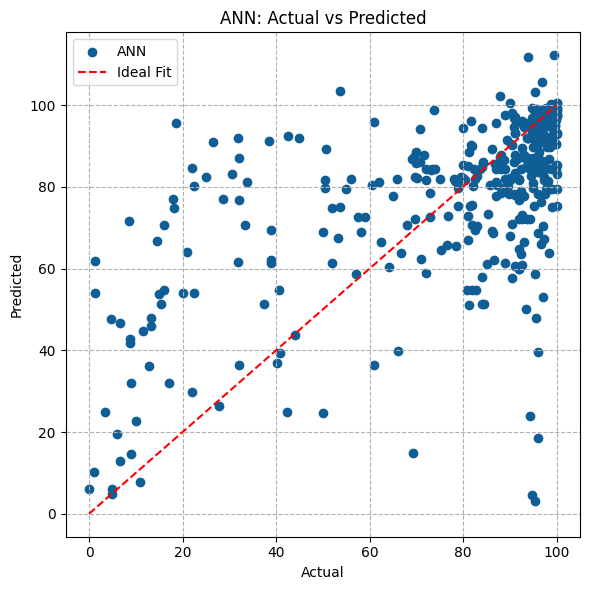

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, color="#105e96", label='ANN')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', label='Ideal Fit')
plt.xlabel("Actual")
plt.ylabel("Predicted") 
plt.title("ANN: Actual vs Predicted")
plt.legend()
plt.grid(True, linestyle='--')
plt.tight_layout()
plt.show()


,feature,mean_abs_shap
0,Compound Mw (g/mol),15.043389
5,compound size (nm),10.893205
2,Pressure (kPa),7.087795
3,Measurement time (min),6.373659
1,Compound Kow,6.219274
4,Initial concentration of compound (mg/L),1.047019


/tmp/ipykernel_14822/464748988.py:31: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


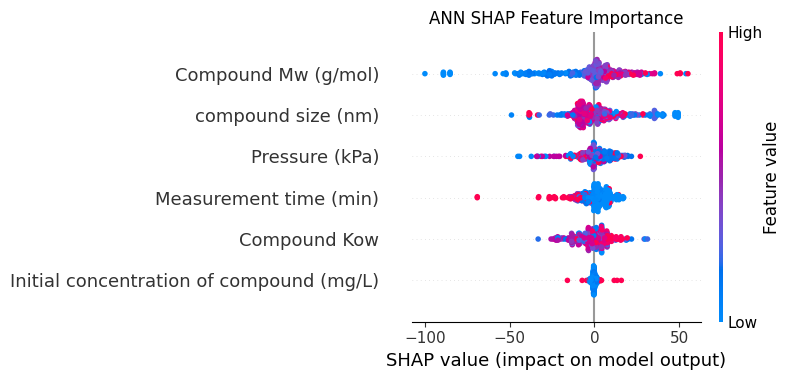

/tmp/ipykernel_14822/464748988.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


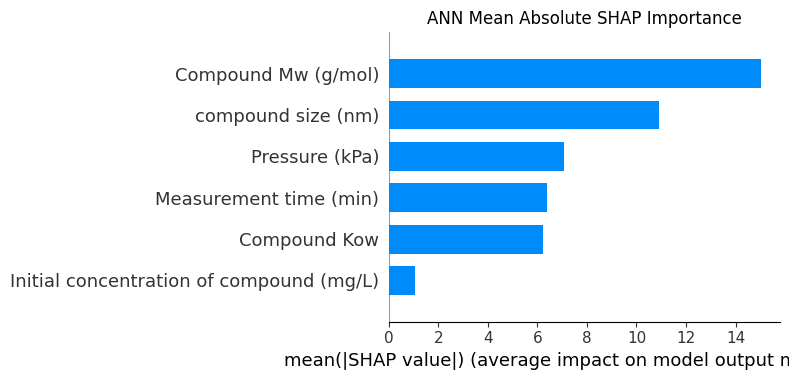

In [15]:
model.eval()

# Use tensors on the same device as the ANN
background = X_train.detach()
explain_data = X_test.detach()

explainer = shap.DeepExplainer(model, background)
raw_shap_values = explainer.shap_values(explain_data)

# Handle SHAP's list/extra-output-dimension formats
if isinstance(raw_shap_values, list):
    shap_values = raw_shap_values[0]
else:
    shap_values = raw_shap_values

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 0]

features = explain_data.cpu().numpy()

importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(importance)

# SHAP beeswarm plot
shap.summary_plot(
    shap_values,
    features=features,
    feature_names=X.columns,
    show=False
)
plt.title("ANN SHAP Feature Importance")
plt.tight_layout()
plt.show()

# SHAP bar plot
shap.summary_plot(
    shap_values,
    features=features,
    feature_names=X.columns,
    plot_type="bar",
    show=False
)
plt.title("ANN Mean Absolute SHAP Importance")
plt.tight_layout()
plt.show()